# A/B-тест новой посадочной страницы

Цель: проверить, меняет ли новая посадочная страница конверсию пользователей.

Ноутбук пересоздаёт базу DuckDB из CSV, выполняет SQL-скрипты из папки `sql/`
и проводит статистический анализ. Краткие выводы находятся в README.

In [1]:
from pathlib import Path
import os
import duckdb
import pandas as pd
import numpy as np
from scipy import stats
from statsmodels.stats.proportion import proportions_ztest, confint_proportions_2indep
from statsmodels.stats.power import NormalIndPower
from statsmodels.stats.proportion import proportion_effectsize
from IPython.display import display, Markdown

ROOT = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
os.chdir(ROOT)
con = duckdb.connect(str(ROOT / "ab_test.duckdb"))
Path("figures").mkdir(exist_ok=True)

## 1. Загрузка, валидация и очистка данных

Скрипты выполняются по порядку:
- `01_ingest.sql`: загрузка сырых данных с явной схемой;
- `02_validation.sql`: проверки качества данных (V1–V7);
- `03_cleaning.sql`: очистка, реестр исключённых строк и проверки результата (P1–P3);
- `04_metrics.sql`: метрики для анализа (M1–M6).

In [2]:
def run_sql_file(path):
    """Run each statement in the file and show the result of every SELECT.
    The title is the first '-- V..', '-- M..' or '-- P..' comment in the block."""
    text = Path(path).read_text(encoding="utf-8")
    for chunk in text.split(";"):
        lines = chunk.strip().splitlines()
        code = [l for l in lines if not l.strip().startswith("--")]
        if not "".join(code).strip():
            continue
        title = next((l.strip("- ").strip() for l in lines
                      if l.strip().startswith(("-- V", "-- M", "-- P"))), None)
        rel = con.sql(chunk)
        if rel is not None and rel.columns:                     
            if title:
                display(Markdown(f"**{title}**"))
            display(rel.df())

for f in ["01_ingest", "02_validation", "03_cleaning", "04_metrics"]:
    display(Markdown(f"### {f}.sql"))
    run_sql_file(ROOT / "sql" / f"{f}.sql")

### 01_ingest.sql

### 02_validation.sql

**V1. Объём данных: строки, уникальные пользователи, дубли**

,rows_total,users_total,duplicate_rows
0,294478,290584,3894


**V2. Перекрёстная таблица group x landing_page, проверка работы сплит-системы**

,ab_group,landing_page,users
0,control,new_page,1928
1,control,old_page,145274
2,treatment,new_page,145311
3,treatment,old_page,1965


... (34 outputs left out)

**M5. Конверсия по странам (исследовательский разрез)**

,country,ab_group,users,conversions,cr_pct
0,CA,control,7198,855.0,11.878
1,CA,treatment,7301,817.0,11.190
2,UK,control,36360,4364.0,12.002
3,UK,treatment,36106,4375.0,12.117
4,US,control,101716,12270.0,12.063
5,US,treatment,101903,12072.0,11.847


**M6. Покрытие стран после очистки — проверка перед разрезом M5**

,check_name,rows_found
0,clean без страновой записи,0
1,страны вне clean,0


**Результаты валидации**

- В данных 294 478 строк и 290 584 уникальных пользователя.
- В 3 893 строках группа не совпадает с показанной страницей: пользователь из control
  видел new_page или пользователь из treatment видел old_page. Для таких строк неизвестно,
  какой вариант на самом деле влиял на пользователя, поэтому они исключены.
- Дубли пользователей почти полностью вызваны той же ошибкой. После удаления
  несоответствий остался 1 дубль, для него сохранена первая по времени строка.
- Пропусков нет, значения во всех колонках допустимые, все пользователи есть в `countries.csv`.
- Первые и последние сутки неполные. Тест начался и закончился в середине дня и длился
  ровно 22 суток, поэтому это не сбой логирования. Данные этих дней сохранены,
  в разделе 6 результат проверен без них.

Итог: 290 584 пользователя, одна строка на пользователя. Все исключённые строки
сохранены в `excluded_ab_data` с причиной исключения.

## 2. Проверка Sample Ratio Mismatch

При корректной работе системы распределения группы должны быть примерно равны (50/50).
Значимое отклонение (SRM) означает, что распределение сломано или пользователи теряются
в одной из групп. В таком случае группы перестают быть сравнимыми, и разнице конверсий
нельзя доверять.

Проверка: критерий хи-квадрат на размерах групп до и после очистки.
Порог p < 0.001: такую проверку запускают в каждом эксперименте,
и строгий порог снижает число ложных тревог.

In [3]:
srm = con.sql("""
    SELECT 'raw' AS stage, ab_group, COUNT(*) AS n FROM raw_ab_data GROUP BY ab_group
    UNION ALL
    SELECT 'clean', ab_group, COUNT(*) FROM clean_ab_data GROUP BY ab_group
""").df()

for stage, part in srm.groupby("stage"):
    n = part.sort_values("ab_group")["n"].to_numpy()
    chi2, p = stats.chisquare(n)          # ожидание 50/50 по умолчанию
    print(f"{stage}: n={n}, chi2={chi2:.3f}, p={p:.4f}, "
          f"доля treatment={n[1]/n.sum():.4f}")

clean: n=[145274 145310], chi2=0.004, p=0.9468, доля treatment=0.5001
raw: n=[147202 147276], chi2=0.019, p=0.8915, доля treatment=0.5001


**Вывод:** p = 0.89 на сырых данных и p = 0.95 после очистки, доля тестовой группы 50.01%.
Распределение корректное, очистка не нарушила баланс групп.

## 3. Дизайн эксперимента и мощность

- H0: конверсия в группах одинаковая. H1: конверсия различается.
  Тест двусторонний, так как новая страница может как улучшить, так и ухудшить конверсию.
- α = 0.05: допустимая вероятность найти эффект, которого нет (ошибка I рода).
- Мощность 80%: вероятность обнаружить эффект, если он не меньше MDE.
- MDE = 1 п.п. от базовой конверсии 12%: минимальный эффект, ради которого
  имеет смысл внедрять изменение.

Базовая конверсия взята из контрольной группы этих же данных (12.04%, округлено до 12%).
Поэтому расчёт сделан постфактум. При планировании реального теста
базовую конверсию берут из исторических данных до запуска.

In [4]:
p0 = 0.12          # базовая конверсия контроля (M2), округлено
mde_abs = 0.01     # +1 п.п.
alpha, power = 0.05, 0.80

h = proportion_effectsize(p0 + mde_abs, p0)
n_req = NormalIndPower().solve_power(
    effect_size=h, alpha=alpha, power=power, ratio=1, alternative="two-sided")
print(f"Требуется на группу: {np.ceil(n_req):.0f}")

n_actual = con.sql(
    "SELECT MIN(n) FROM (SELECT COUNT(*) AS n FROM clean_ab_data GROUP BY ab_group)"
).fetchone()[0]

h_min = NormalIndPower().solve_power(
    nobs1=n_actual, alpha=alpha, power=power, ratio=1, alternative="two-sided")

from scipy.optimize import brentq
mde_detectable = brentq(
    lambda d: proportion_effectsize(p0 + d, p0) - h_min, 1e-6, 0.5)
print(f"Фактически n={n_actual}, обнаружим эффект от {mde_detectable*100:.2f} п.п.")

Требуется на группу: 17164
Фактически n=145274, обнаружим эффект от 0.34 п.п.


**Вывод:** для MDE 1 п.п. нужно 17 164 пользователя на группу, в данных 145 274,
то есть в 8.5 раза больше. С такой выборкой тест обнаружил бы с вероятностью 80%
изменение конверсии от 0.34 п.п. Если результат окажется незначимым,
это не объясняется нехваткой данных для эффектов такого размера.

## 4. Основной тест

Метрика бинарная (пользователь сконвертировался или нет), группы независимые и большие,
поэтому используется z-тест для двух долей.

Разница считается как "тест - контроль": отрицательное значение означает,
что новая страница хуже старой.

95% доверительный интервал разницы рассчитан методом Ньюкомба.
Для сравнения интервал Вальда посчитан вручную по формуле стандартной ошибки.

In [5]:
grp = (con.sql("""
    SELECT ab_group, COUNT(*) AS n, SUM(converted) AS conv
    FROM clean_ab_data GROUP BY ab_group
""").df().set_index("ab_group").loc[["control", "treatment"]])

n_c, n_t = int(grp.loc["control", "n"]),  int(grp.loc["treatment", "n"])
x_c, x_t = int(grp.loc["control", "conv"]), int(grp.loc["treatment", "conv"])
cr_c, cr_t = x_c / n_c, x_t / n_t

# count[0] = treatment, разница считается как treatment - control
zstat, pval = proportions_ztest(
    count=np.array([x_t, x_c]), nobs=np.array([n_t, n_c]),
    alternative="two-sided")

ci_low, ci_high = confint_proportions_2indep(
    x_t, n_t, x_c, n_c, compare="diff", method="newcomb")

print(f"control:   {cr_c:.4%}  ({x_c}/{n_c})")
print(f"treatment: {cr_t:.4%}  ({x_t}/{n_t})")
print(f"разница (treatment - control): {(cr_t-cr_c)*100:+.3f} п.п.")
print(f"z = {zstat:.3f}, p = {pval:.4f}")
print(f"95% ДИ (Ньюкомб): [{(ci_low)*100:+.3f}; {(ci_high)*100:+.3f}] п.п.")

control:   12.0386%  (17489/145274)
treatment: 11.8808%  (17264/145310)
разница (treatment - control): -0.158 п.п.
z = -1.311, p = 0.1899
95% ДИ (Ньюкомб): [-0.394; +0.078] п.п.


In [6]:
# Интервал Вальда вручную для сравнения с интервалом Ньюкомба
se = np.sqrt(cr_t * (1 - cr_t) / n_t + cr_c * (1 - cr_c) / n_c)
d  = cr_t - cr_c
z_crit = stats.norm.ppf(0.975)
print(f"SE = {se*100:.4f} п.п., CI Вальда: "
      f"[{(d - z_crit*se)*100:+.3f}; {(d + z_crit*se)*100:+.3f}] п.п.")

SE = 0.1204 п.п., CI Вальда: [-0.394; +0.078] п.п.


**Вывод:** конверсия 12.04% в контроле и 11.88% в тесте, разница −0.16 п.п., p = 0.19.
95% ДИ [−0.39; +0.08] п.п. содержит ноль, поэтому H0 не отвергается.
Интервалы Ньюкомба и Вальда практически совпадают, как и ожидается при такой выборке.

Верхняя граница интервала (+0.08 п.п.) намного ниже целевого MDE в 1 п.п.
Даже в лучшем для новой страницы случае эффект слишком мал, чтобы её внедрять.

## 5. Визуализация

Конверсия по группам с 95% доверительными интервалами (Уилсон).
Интервалы групп перекрываются, что согласуется с результатом теста.

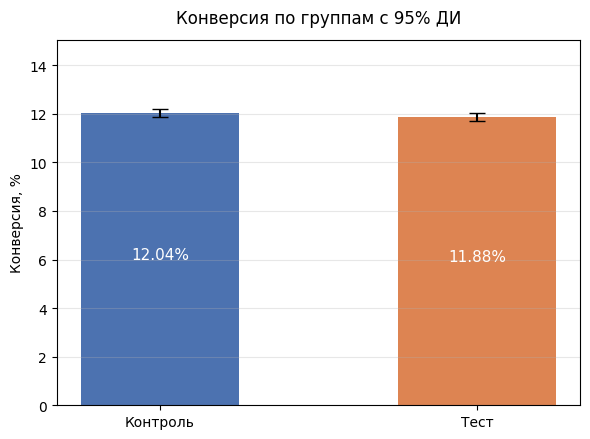

In [7]:
import matplotlib.pyplot as plt

# График 1: конверсия по группам с 95% ДИ
from statsmodels.stats.proportion import proportion_confint
ci = proportion_confint(np.array([x_c, x_t]), np.array([n_c, n_t]), method="wilson")
rates = np.array([cr_c, cr_t]) * 100
err = np.vstack([rates - ci[0] * 100, ci[1] * 100 - rates])

fig, ax = plt.subplots(figsize=(6, 4.5))
ax.bar(["Контроль", "Тест"], rates, yerr=err, capsize=6,
       color=["#4C72B0", "#DD8452"], width=0.5)
ax.set_ylabel("Конверсия, %")
ax.set_title("Конверсия по группам с 95% ДИ", pad=12)
ax.set_ylim(0, max(rates) * 1.25)
for i, r in enumerate(rates):
    ax.text(i, r / 2, f"{r:.2f}%", ha="center", color="white", fontsize=11)
ax.grid(axis="y", alpha=0.3)
fig.tight_layout()
fig.savefig("figures/conversion_by_group.png", dpi=150)
plt.show()

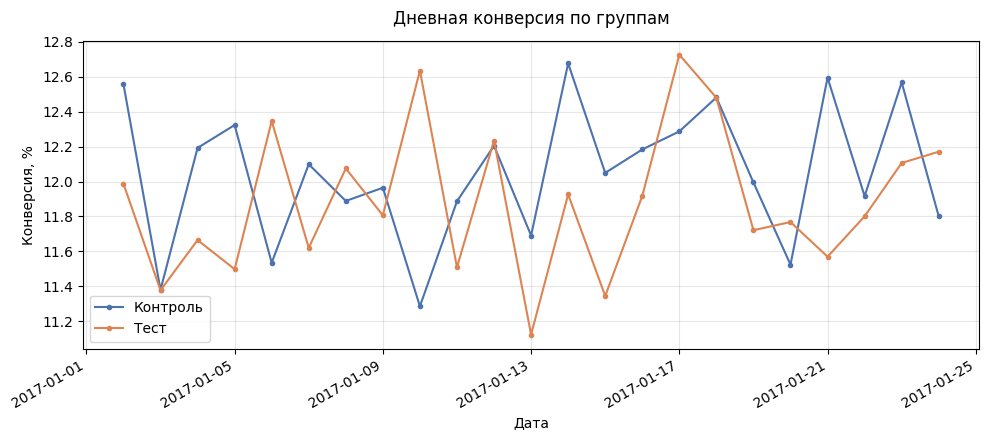

            min   max
ab_group             
control    11.3  12.7
treatment  11.1  12.7


In [8]:
# График 2: конверсия по дням
daily = con.sql("""
    SELECT event_ts::DATE AS event_date, ab_group,
           COUNT(*) AS users, SUM(converted) AS conversions
    FROM clean_ab_data GROUP BY 1, 2 ORDER BY 1, 2
""").df()
daily["cr_pct"] = daily.conversions / daily.users * 100
piv = daily.pivot(index="event_date", columns="ab_group", values="cr_pct")

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.plot(piv.index, piv["control"],   marker="o", ms=3, label="Контроль", color="#4C72B0")
ax.plot(piv.index, piv["treatment"], marker="o", ms=3, label="Тест",     color="#DD8452")
ax.set_ylabel("Конверсия, %")
ax.set_xlabel("Дата")
ax.set_title("Дневная конверсия по группам", pad=12)
ax.legend()
ax.grid(alpha=0.3)
fig.autofmt_xdate()
fig.tight_layout()
fig.savefig("figures/daily_conversion.png", dpi=150)
plt.show()
print(daily.groupby("ab_group")["cr_pct"].agg(["min", "max"]).round(1))

Дневная конверсия колеблется в пределах 11.1-12.7%, линии групп многократно
пересекаются, и ни одна группа не лидирует стабильно. Заметного тренда
(например, эффекта новизны в первые дни) не видно.

## 6. Проверка устойчивости: без неполных дней

Повторяем тест без первых и последних суток, чтобы убедиться,
что решение сохранить эти дни не влияет на вывод.

In [9]:
# Проверка устойчивости: исключаем неполные первый и последний дни
edge = (con.sql("""
    SELECT ab_group, COUNT(*) AS n, SUM(converted) AS conv
    FROM clean_ab_data
    WHERE event_ts::DATE > (SELECT MIN(event_ts::DATE) FROM clean_ab_data)
      AND event_ts::DATE < (SELECT MAX(event_ts::DATE) FROM clean_ab_data)
    GROUP BY ab_group
""").df().set_index("ab_group").loc[["treatment", "control"]])

xt, nt = int(edge.loc["treatment", "conv"]), int(edge.loc["treatment", "n"])
xc, nc = int(edge.loc["control", "conv"]),   int(edge.loc["control", "n"])
_, p_e = proportions_ztest([xt, xc], [nt, nc])
lo_e, hi_e = confint_proportions_2indep(xt, nt, xc, nc, compare="diff", method="newcomb")
print(f"без крайних дней: разница {(xt/nt - xc/nc)*100:+.3f} п.п., "
      f"p = {p_e:.4f}, ДИ [{lo_e*100:+.3f}; {hi_e*100:+.3f}]")

без крайних дней: разница -0.163 п.п., p = 0.1845, ДИ [-0.405; +0.078]


**Вывод:** без крайних дней разница -0.163 п.п., p = 0.1845,
95% ДИ [-0.405; +0.078] п.п.
Тогда как с крайними днями было: разница -0.158 п.п., p = 0.1899,
95% ДИ [-0.394; +0.078] п.п.
Вывод не меняется.

## 7. Bootstrap

Проверка результата без предположения о нормальности распределения.
Выборки пользователей генерируются с возвращением 10 000 раз, для каждой считается
разница конверсий, а 95% интервал берётся по 2.5 и 97.5 перцентилям.

Для бинарной метрики число конверсий в такой выборке распределено как Binomial(n, p̂),
поэтому оно генерируется напрямую. Это эквивалентно ресемплированию пользователей,
но не требует создавать массив 10 000 x 145 000.

Bootstrap 95% ДИ: [-0.394; +0.081] п.п.


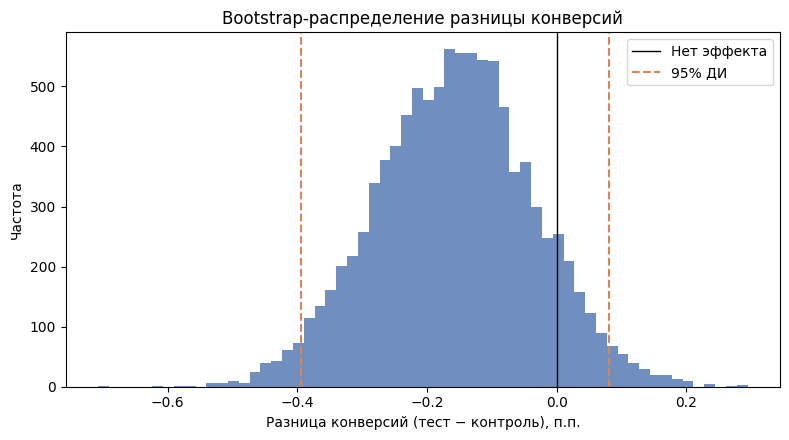

In [10]:
rng = np.random.default_rng(42)
B = 10_000
boot_diff = (rng.binomial(n_t, cr_t, B) / n_t - rng.binomial(n_c, cr_c, B) / n_c) * 100
b_lo, b_hi = np.percentile(boot_diff, [2.5, 97.5])
print(f"Bootstrap 95% ДИ: [{b_lo:+.3f}; {b_hi:+.3f}] п.п.")

fig, ax = plt.subplots(figsize=(8, 4.5))
ax.hist(boot_diff, bins=60, color="#4C72B0", alpha=0.8)
ax.axvline(0, color="black", lw=1, label="Нет эффекта")
ax.axvline(b_lo, color="#DD8452", ls="--", label="95% ДИ")
ax.axvline(b_hi, color="#DD8452", ls="--")
ax.set_xlabel("Разница конверсий (тест − контроль), п.п.")
ax.set_ylabel("Частота")
ax.set_title("Bootstrap-распределение разницы конверсий")
ax.legend()
fig.tight_layout()
fig.savefig("figures/bootstrap_diff.png", dpi=150)
plt.show()

**Вывод:** bootstrap-интервал [-0.394; +0.081] п.п. совпадает с аналитическим [−0.39; +0.08] п.п.

## 8. Вывод и рекомендация

Новая посадочная страница не показала значимого изменения конверсии:
−0.16 п.п. (p = 0.19), 95% ДИ [−0.39; +0.08] п.п. Тест обладал достаточной мощностью,
чтобы обнаружить эффект от 0.34 п.п., а верхняя граница интервала намного ниже
целевого MDE в 1 п.п.

**Рекомендация:** не внедрять новую страницу. Даже в лучшем случае ожидаемый
выигрыш пренебрежимо мал, а точечная оценка немного отрицательная.

**Ограничения:**
- Тест длился 22 дня. Эффект новизны или привыкания мог не успеть проявиться.
- Исключено 1.3% строк с несоответствием группы и страницы. Если ошибка затрагивала
  определённый тип пользователей, это могло немного сместить группы.
- В данных нет окна конверсии: пользователи последних часов теста имели меньше времени,
  чтобы сконвертироваться (в обеих группах одинаково, поэтому сравнение не искажается).
- Базовая конверсия для расчёта мощности взята из этих же данных.
- Анализировалась одна метрика, без guardrail-метрик (например, отказов или выручки).